In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
dat = np.loadtxt('/Users/ssatyavolu/projects/proximity/1D-radiative-transfer/z5.95LOS0tq1mag-27.00_tep_1Myr1fd.txt')

Text(0, 0.5, 'Temperature (K)')

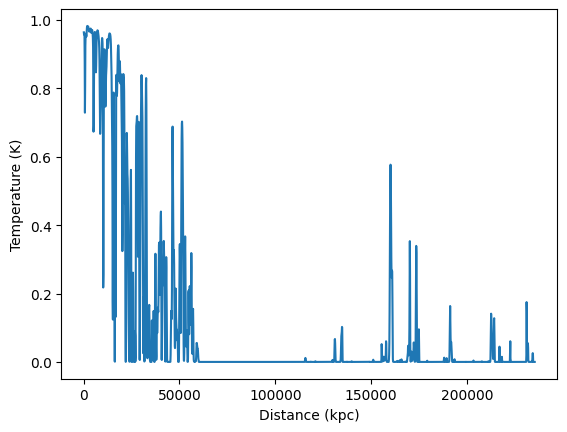

In [19]:
plt.plot(dat[:,0], np.exp(-dat[:,6]))
plt.xlabel('Distance (kpc)')
plt.ylabel('Temperature (K)')



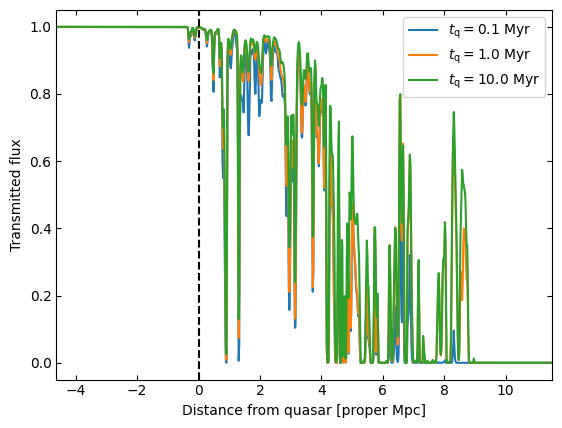

In [6]:

tq = [1e-01,1e+00,1e+01]
los = 110  # to choose a sightline, input any number between 0-485.
h = 0.678
z = 5.76 # redshift of our simulation snapshot 


for inp in range(3):
	filename = 'outputs/j0148_z5p98_m2739/section31_grid/npy/qso_z5.76_zqso5.98_m-27.39_tq%0.0e_los.npy'%tq[inp]
	file = np.load(filename)
	# Read parameters
	x_ckpc = file[los,:,0]  	# distance from quasar (Lyman alpha peak) in comoving kpc
	x_HI = file[los,:,1] 		# x_HI= n_HI/n_H
	T = file[los,:,2] 			# Temperature in K
	x_HeI = file[los,:,3] 		# x_HeI = 1-x_HeII-x_HeIII
	x_HeII = file[los,:,4] 		# x_HeII = n_HeII/n_He
	x_HeIII = file[los,:,5] 	# x_HeIII = n_HeIII/n_He
	Tau = file[los,:,6] 		# Optical depth
	Flux = np.exp(-Tau) 		# Flux F = exp(-Tau)

	zero = (x_ckpc[1]-x_ckpc[0])*256/1000/(1+z) # location of Lyman alpha line 
	x_pMpc = x_ckpc/1000/(1+z) - zero # distance in proper Mpc

	plt.plot(x_pMpc,Flux,label=r'$t_{\mathrm{q}}=%0.1f$ Myr'%tq[inp])
	plt.xlim(x_pMpc.min(),x_pMpc.max())


plt.axvline(x=0,linestyle='--',color='k')
plt.xlabel('Distance from quasar [proper Mpc]')
plt.ylabel('Transmitted flux')
plt.legend()
plt.tick_params(direction='in',which='both',top=True,right=True)
plt.show()